# **Image Classification with Random Forests**

Paper records lock away historical value; automated ingestion pipelines unlock it. To transition from manual filing cabinets to an integrated digital archive, the Ministry of Agriculture requires an engine capable of parsing physical survey data. In this project, you construct a scalable document digitization component by training a `RandomForestClassifier` on the Maji Ndogo Digit Calibration Bank — a purpose-built digit benchmark assembled by the ministry's digitisation pilot team. You will configure parametric subset extraction, normalize raw pixel intensity matrices to uniform numerical feature scales, and deploy multi-class confusion evaluation metrics to target classification bottlenecks. This establishes the structural pattern-recognition framework necessary to safely ingest legacy regional records prior to unlocking high-stakes national field databases.


The Ministry of Agriculture's Maji Ndogo programme holds a critical problem: decades of farm survey records exist only on paper. Thousands of handwritten field IDs, yield measurements, and crop notes are locked away in filing cabinets across the country, unable to feed into the national agricultural database.

Before the ministry can trust us with the national farm survey database — which we will work with in Module 3 — they need us to prove something first: that we can build a reliable automated system for reading digits scanned off paper forms. This is the foundation of any digitisation pipeline. If we can accurately classify digits, the ministry can begin scanning and automatically ingesting decades of archived paper surveys.

Your assignment this module is to build a **Random Forest image classifier** capable of recognising digits. Rather than risk real, irreplaceable field archives on an unproven pipeline, the digitisation pilot team built a calibration set first: the **Maji Ndogo Digit Calibration Bank** — 35,000 digit images rendered from the actual typefaces used on the ministry's historical paper forms, each one distorted with the rotation, skew, and scan noise you'd expect from decades-old documents run through a low-cost scanner. It is deliberately messy, for the same reason a pilot's flight simulator is deliberately turbulent: if the model can handle this, it can handle the real archive. The model you build here is the same type of component that would sit at the front of a real document digitisation system.

By the end of this project, the ministry will have confidence in your classification skills, and you will have earned access to the full agricultural data in Module 3.

## __[Imports]()__

Let's load the libraries we need.

In [2]:
import numpy as np
import pandas as pd
import gzip  # Used to extract the compressed digit images
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

 ## __The Dataset__

We are using the **Maji Ndogo Digit Calibration Bank** — a purpose-built collection of digit images (0–9) assembled specifically to stress-test this pipeline before it ever touches a real archive. It requires little to no preprocessing, making it the ideal starting point for building our digitisation component.

The four files are provided alongside this notebook — no download required. The cell below simply confirms they're present in your working directory.
   

In [3]:
import os


In [ ]:
DATA_FILES = [
    "train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz",
]

missing = [file for file in DATA_FILES if not os.path.exists(file)]
if missing:
    raise FileNotFoundError(
        f"Missing data file(s): {missing}. Make sure they are in the same "
        "folder as this notebook."
    )

print("All four Digit Calibration Bank files are present.")

All four Digit Calibration Bank files are present.


### __Helper functions to extract the data__

In [5]:
def extract_data(filename, num_images, IMAGE_WIDTH):
    """Extract the images into a 2D array [image index, flattened pixels]."""
    with gzip.open(filename) as bytestream:
        bytestream.read(16)
        buf = bytestream.read(IMAGE_WIDTH * IMAGE_WIDTH * num_images)
        data = np.frombuffer(buf, dtype=np.uint8).astype(np.float32)
        data = data.reshape(num_images, IMAGE_WIDTH * IMAGE_WIDTH)
        return data


def extract_labels(filename, num_images):
    """Extract the labels into a vector of int64 label IDs."""
    with gzip.open(filename) as bytestream:
        bytestream.read(8)
        buf = bytestream.read(1 * num_images)
        labels = np.frombuffer(buf, dtype=np.uint8).astype(np.int64)
    return labels

## **Challenge 1: Extracting the Data**

The Digit Calibration Bank ships as four separate gzip files — two for training and two for testing, one for images and one for labels in each pair. Before we can train anything, we need to unpack them into numpy arrays and normalise the pixel values so every feature lives on the same scale. This is the data ingestion step: the moment the raw bytes on disk become the matrices our model will learn from.

Sanaa needs this pipeline to be parameterised. The full training bank has 30,000 images and training on all of them takes time. During development we use a smaller subset; once we are confident the model works, we scale up. Your function must accept the subset size as an argument so we can swap it out without rewriting any code.

### **Task**

Write a function `get_data` that uses the helper functions above to extract a specified number of images and their labels from the gzip files.

**Function specifications:**
- Takes two integers as input: `num_train_images` and `num_test_images`.
- Returns two tuples of the form `(X_train, y_train), (X_test, y_test)`.
- Normalises image pixel values from the range 0–255 to the range 0–1.
- The images are **28×28 pixels**.
- Do **not** shuffle the data — we keep the order fixed so all results are reproducible.

> **Note:** The filenames expected by your function are:
> - `'train-images-idx3-ubyte.gz'`
> - `'train-labels-idx1-ubyte.gz'`
> - `'t10k-images-idx3-ubyte.gz'`
> - `'t10k-labels-idx1-ubyte.gz'`

    

In [6]:
def get_data(num_train_images, num_test_images):
    image_width = 28

    # Extract training data
    X_train = extract_data(
        "train-images-idx3-ubyte.gz",
        num_train_images,
        image_width
    )

    y_train = extract_labels(
        "train-labels-idx1-ubyte.gz",
        num_train_images
    )

    # Extract test data
    X_test = extract_data(
        "t10k-images-idx3-ubyte.gz",
        num_test_images,
        image_width
    )

    y_test = extract_labels(
        "t10k-labels-idx1-ubyte.gz",
        num_test_images
    )

    # Normalise pixel values from 0–255 to 0–1
    X_train /= 255.0
    X_test /= 255.0

    return (X_train, y_train), (X_test, y_test)

In [7]:
(X_train, y_train), (X_test, y_test) = get_data(5000, 1000)

print(y_train.shape)
print(y_test.shape)
print(X_train.shape)
print(X_test.shape)

(5000,)
(1000,)
(5000, 784)
(1000, 784)


Label: 8


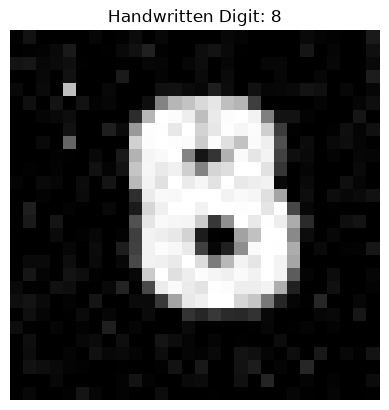

In [11]:
image_index = 9

print("Label:", y_train[image_index])

reshaped_image = X_train[image_index].reshape(28, 28)

plt.imshow(reshaped_image, cmap="gray")
plt.title(f"Handwritten Digit: {y_train[image_index]}")
plt.axis("off")
plt.show()

## __Challenge 2: Training the Model__

The data is loaded, normalised, and ready. Now we hand it to a classifier. We are using sklearn's `RandomForestClassifier` — a homogeneous ensemble that grows many decision trees on random bootstrap samples of the training data and lets them vote on the final prediction. A single decision tree is brittle; one bad split near the root and the whole tree goes wrong. The forest averages out that instability across all its trees.

This is the same ensemble architecture Sanaa wants to use on the Maji Ndogo field registry in Module 3. We are proving the method works on the calibration bank first — a clean, well-understood benchmark — before we trust it with real agricultural decisions.

### __Task__

Write a function `train_model` that:
- Takes two numpy arrays as input: `X_train` and `y_train`.
- Returns a fitted `RandomForestClassifier` with:
    - `n_estimators = 20`
    - `random_state = 42`

In [12]:
def train_model(X_train, y_train):
    model = RandomForestClassifier(
        n_estimators=20,
        random_state=42
    )

    model.fit(X_train, y_train)

    return model

In [13]:
clf = train_model(X_train, y_train)

print(f"Model type: {type(clf).__name__}")
print(f"Number of estimators: {clf.n_estimators}")

Model type: RandomForestClassifier
Number of estimators: 20


## **Challenge 3: Calculating Accuracy**

The model is trained. Before we hand anything to Sanaa, we need to know how well it performs on data it has never seen. Accuracy — the proportion of test images classified correctly — is the first number she will ask for. It gives us a single figure that anchors the conversation: is this model worth discussing further, or do we go back to the drawing board?

A note of caution that we will return to in Challenge 4: accuracy can be misleading when classes are imbalanced. For this calibration bank the ten digit classes are roughly balanced, so accuracy is a fair summary here. Keep that caveat in mind for the Maji Ndogo work ahead.

### __Task__

Write a function `calculate_accuracy` that:
- Takes the fitted model `clf` and two numpy arrays `X_test`, `y_test` as input.
- Returns a **float** representing the accuracy (between 0 and 1).

### __Expected Output__
```
0.891

In [14]:
def calculate_accuracy(clf, X_test, y_test):
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    return float(accuracy)

In [15]:
print(calculate_accuracy(clf, X_test, y_test))

0.891


## __Challenge 4: Classification Report__

Accuracy alone doesn't tell the full story. A classification report shows us **precision**, **recall**, and **F1-score** for each digit class — revealing exactly where the model makes Type I and Type II errors. This is critical information for the ministry: misreading a `1` as a `7` in a field ID would link a survey record to the wrong farm.

Consider what a precision error means in this context — we flag an image as a particular digit when it is actually something else. And a recall error means we fail to recognise a digit that was genuinely there. Both types of mistake introduce corruption into the digitised survey archive. Sanaa needs to see the full breakdown before she signs off on deploying this component.

### __Task__

Write a function `get_class_report` that:
- Takes the fitted model `clf` and two numpy arrays `X_test`, `y_test` as input.
- Returns a classification report.

> **Hint:** sklearn has a `classification_report` function.

In [16]:
def get_class_report(clf, X_test, y_test):
    y_pred = clf.predict(X_test)

    report = classification_report(
        y_test,
        y_pred
    )

    return report

In [17]:
print(get_class_report(clf, X_test, y_test))

              precision    recall  f1-score   support

           0       0.90      0.98      0.94       105
           1       0.90      0.93      0.92        89
           2       0.93      0.94      0.94       102
           3       0.87      0.93      0.90       103
           4       0.89      0.98      0.93        87
           5       0.91      0.77      0.83       107
           6       0.89      0.78      0.83       109
           7       0.90      0.97      0.93       102
           8       0.79      0.86      0.82        99
           9       0.94      0.79      0.86        97

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000



## __[Plotting the Results]()__

Let's visually inspect some predictions to confirm the model is working correctly.

Predicted Label:  0


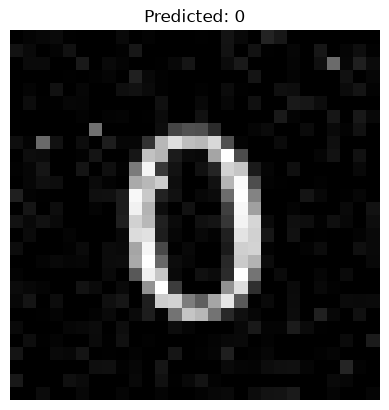

In [ ]:
preds = clf.predict(X_test)
image_index_1 = 1
print('Predicted Label: ', preds[image_index_1])
plt.imshow(X_test[image_index_1].reshape((28, 28)), cmap='gray')
plt.title(f'Predicted: {preds[image_index_1]}')
plt.axis('off')
plt.show()

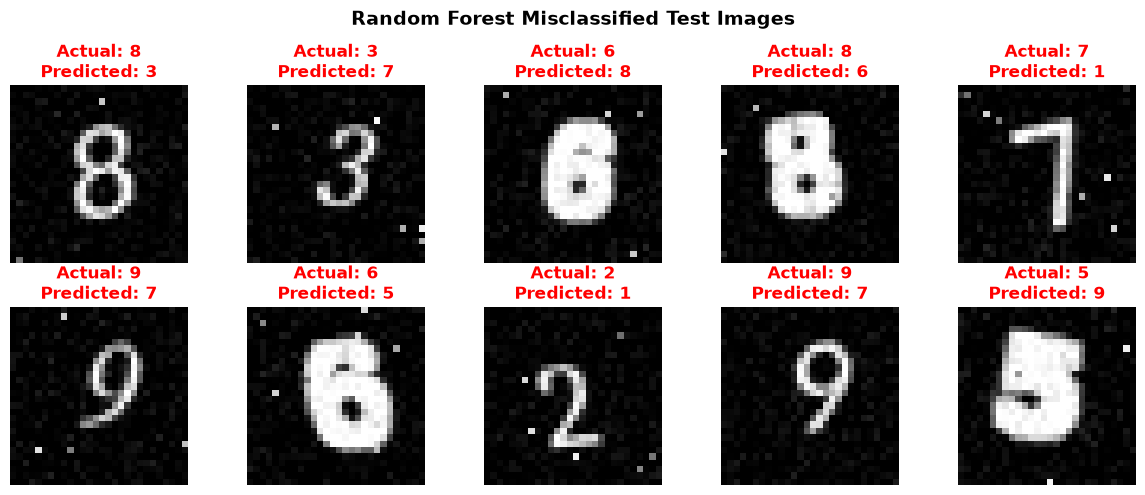

In [18]:

# Generate predictions
predictions = clf.predict(X_test)

# Identify misclassified observations
misclassified_indices = np.flatnonzero(
    y_test != predictions
)

# Number of errors to display
num_errors = min(10, len(misclassified_indices))

# Create figure
fig, axes = plt.subplots(
    2,
    5,
    figsize=(12, 5)
)

axes = axes.ravel()

# Display misclassified images
for ax, image_index in zip(
    axes[:num_errors],
    misclassified_indices[:num_errors]
):
    actual_label = y_test[image_index]
    predicted_label = predictions[image_index]

    ax.imshow(
        X_test[image_index].reshape(28, 28),
        cmap="gray"
    )

    ax.set_title(
        f"Actual: {actual_label}\n"
        f"Predicted: {predicted_label}",
        color="red",
        fontweight="bold"
    )

    # Highlight misclassification
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(3)
        spine.set_edgecolor("red")

    ax.axis("off")

# Hide unused axes
for ax in axes[num_errors:]:
    ax.axis("off")

# Handle perfect classification
if num_errors == 0:
    axes[0].text(
        0.5,
        0.5,
        "No misclassifications",
        ha="center",
        va="center",
        fontsize=14
    )
    axes[0].axis("off")

fig.suptitle(
    "Random Forest Misclassified Test Images",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


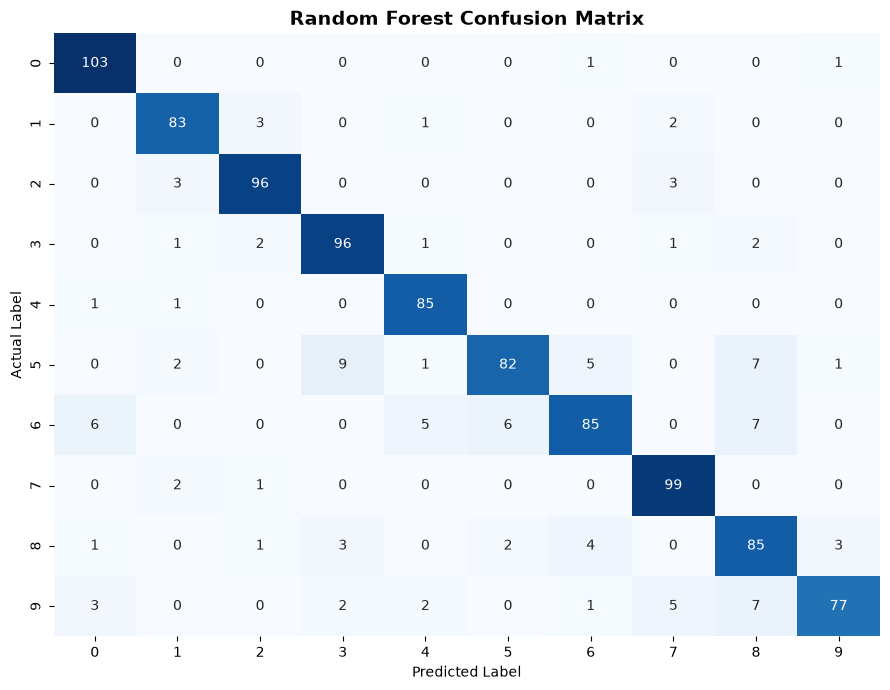

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate predictions
predictions = clf.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, predictions)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=ax
)

ax.set_title(
    "Random Forest Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()